In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

In [5]:
# Load movie information and user ratings

movies = pd.read_csv(r"C:\Users\intel\Desktop\Movie Recoomendation\ml-latest-small\movies.csv")
ratings = pd.read_csv(r"C:\Users\intel\Desktop\Movie Recoomendation\ml-latest-small\ratings.csv")

# Display the first five rows
print("MOVIES DATA")
display(movies.head())

print("RATINGS DATA")
display(ratings.head())

MOVIES DATA


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS DATA


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
print("Movies dataset shape:", movies.shape)
print("Ratings dataset shape:", ratings.shape)

print("\nMovie columns:")
print(movies.columns.tolist())

print("\nRating columns:")
print(ratings.columns.tolist())

print("\nMissing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

Movies dataset shape: (9742, 3)
Ratings dataset shape: (100836, 4)

Movie columns:
['movieId', 'title', 'genres']

Rating columns:
['userId', 'movieId', 'rating', 'timestamp']

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [8]:

print("Movies dataset:", movies.shape)
print("Ratings dataset:", ratings.shape)


print("\nMovies information:")
movies.info()

print("\nRatings information:")
ratings.info()

Movies dataset: (9742, 3)
Ratings dataset: (100836, 4)

Movies information:
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 626.1 KB

Ratings information:
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [9]:
print("First 5 movies:")
display(movies.head())

print("First 5 ratings:")
display(ratings.head())

print("Last 5 movies:")
display(movies.tail())

First 5 movies:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


First 5 ratings:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Last 5 movies:


,movieId,title,genres
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
9739,193585,Flint (2017),Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation
9741,193609,Andrew Dice Clay: Dice Rules (1991),Comedy


In [10]:

display(ratings["rating"].describe())


print("Rating frequency:")
display(ratings["rating"].value_counts().sort_index())

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Rating frequency:


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

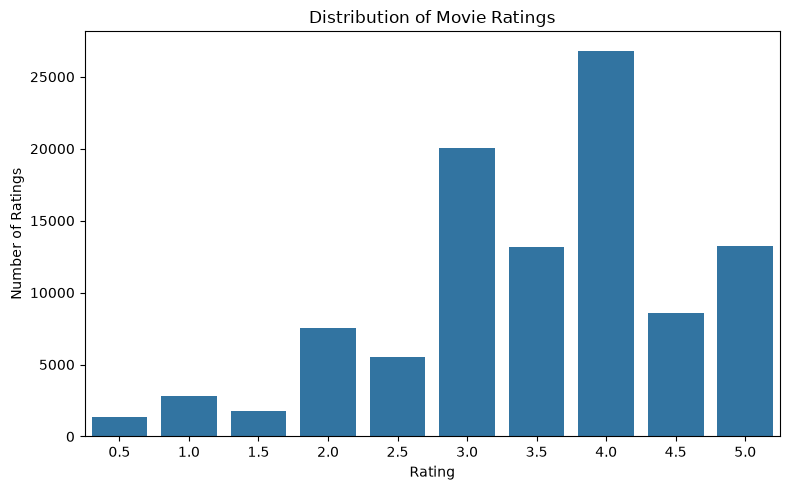

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=ratings, x="rating")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

In [12]:
# Count ratings for each movie
rating_counts = (
    ratings.groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

# Add movie titles
movie_rating_stats = movies.merge(
    rating_counts,
    on="movieId",
    how="left"
)

movie_rating_stats["rating_count"] = (
    movie_rating_stats["rating_count"].fillna(0).astype(int)
)

# Display the top 10 most-rated movies
top_10 = movie_rating_stats.sort_values(
    "rating_count", ascending=False
).head(10)

display(top_10[["title", "rating_count"]])

,title,rating_count
314,Forrest Gump (1994),329
277,"Shawshank Redemption, The (1994)",317
257,Pulp Fiction (1994),307
510,"Silence of the Lambs, The (1991)",279
1939,"Matrix, The (1999)",278
224,Star Wars: Episode IV - A New Hope (1977),251
418,Jurassic Park (1993),238
97,Braveheart (1995),237
507,Terminator 2: Judgment Day (1991),224
461,Schindler's List (1993),220


In [13]:
print("Missing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [14]:
print("Duplicate movie rows:", movies.duplicated().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())

Duplicate movie rows: 0
Duplicate rating rows: 0


In [15]:
movies_clean = movies.copy()
ratings_clean = ratings.copy()

# Remove completely duplicated rows
movies_clean = movies_clean.drop_duplicates()
ratings_clean = ratings_clean.drop_duplicates()

# Remove rows with missing essential identifiers
movies_clean = movies_clean.dropna(
    subset=["movieId", "title"]
)

ratings_clean = ratings_clean.dropna(
    subset=["userId", "movieId", "rating"]
)

print("Clean movies shape:", movies_clean.shape)
print("Clean ratings shape:", ratings_clean.shape)

Clean movies shape: (9742, 3)
Clean ratings shape: (100836, 4)


In [16]:
# Keep ratings within the valid range and increment
valid_rating = (
    ratings_clean["rating"].between(0.5, 5.0)
    & ((ratings_clean["rating"] * 2) % 1 == 0)
)

ratings_clean = ratings_clean[valid_rating].copy()

print("Rating range:",
      ratings_clean["rating"].min(),
      "to",
      ratings_clean["rating"].max())

print("Remaining rating records:", len(ratings_clean))

Rating range: 0.5 to 5.0
Remaining rating records: 100836


In [17]:
# Replace missing genres with an empty string
movies_clean["genres"] = movies_clean["genres"].fillna("")

# Convert genre strings into binary indicator columns
genre_features = movies_clean["genres"].str.get_dummies(sep="|")

# Combine movie information with genre features
movies_features = pd.concat(
    [
        movies_clean[["movieId", "title"]].reset_index(drop=True),
        genre_features.reset_index(drop=True)
    ],
    axis=1
)

display(movies_features.head())
print("Number of genre features:", genre_features.shape[1])

,movieId,title,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),0,0,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


Number of genre features: 20


In [18]:
movie_stats = (
    ratings_clean.groupby("movieId")
    .agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count")
    )
    .reset_index()
)

movie_stats = movie_stats.merge(
    movies_clean[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

display(
    movie_stats.sort_values(
        "rating_count", ascending=False
    ).head(10)
)

,movieId,average_rating,rating_count,title,genres
314,356,4.164134,329,Forrest Gump (1994),Comedy|Drama|Romance|War
277,318,4.429022,317,"Shawshank Redemption, The (1994)",Crime|Drama
257,296,4.197068,307,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
510,593,4.161290,279,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
1938,2571,4.192446,278,"Matrix, The (1999)",Action|Sci-Fi|Thriller
224,260,4.231076,251,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
418,480,3.750000,238,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
97,110,4.031646,237,Braveheart (1995),Action|Drama|War
507,589,3.970982,224,Terminator 2: Judgment Day (1991),Action|Sci-Fi
461,527,4.225000,220,Schindler's List (1993),Drama|War


In [19]:
from sklearn.preprocessing import StandardScaler

cluster_data = movies_features.merge(
    movie_stats[["movieId", "average_rating", "rating_count"]],
    on="movieId",
    how="left"
)

# Fill missing statistics for movies without ratings
cluster_data[["average_rating", "rating_count"]] = (
    cluster_data[["average_rating", "rating_count"]]
    .fillna(0)
)

# Features used for clustering
feature_columns = (
    genre_features.columns.tolist()
    + ["average_rating", "rating_count"]
)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    cluster_data[feature_columns]
)

print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (9742, 22)


In [20]:
from sklearn.cluster import KMeans

print("K-Means is ready!")
print("Number of movies:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

K-Means is ready!
Number of movies: 9742
Number of features: 22


In [21]:
# Store the WCSS (inertia) for different K values
wcss = []

# Try between 1 and 10 clusters
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS values:", wcss)

WCSS values: [214324.00000000012, 198693.94300877454, 187212.85362216696, 177494.11105348665, 165916.0618116483, 156250.03981016407, 147888.85437290242, 137683.44073999033, 129625.01500602938, 120265.26159044949]


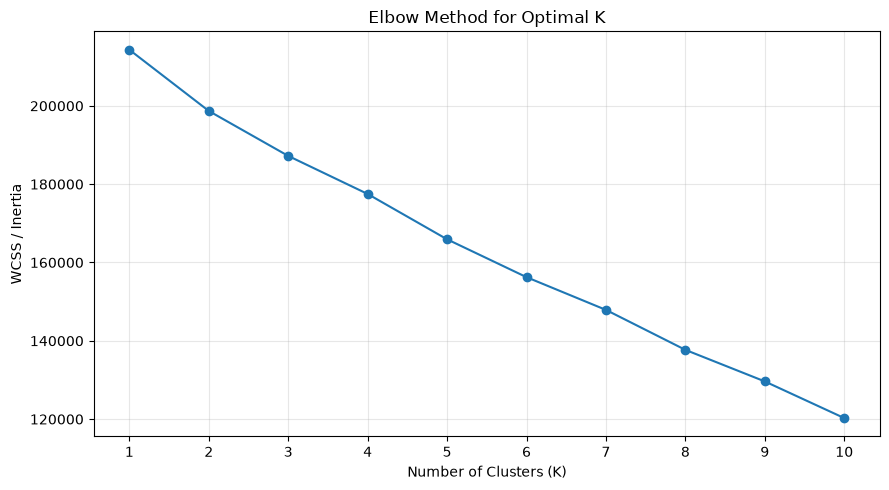

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Change this value after inspecting your Elbow graph
optimal_k = 4

print("Selected number of clusters:", optimal_k)

Selected number of clusters: 4


In [24]:
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train the model and assign a cluster to every movie
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Add the cluster assignments to our prepared data
cluster_data["cluster"] = cluster_labels

print("K-Means training completed!")
display(
    cluster_data[
        ["movieId", "title", "average_rating",
         "rating_count", "cluster"]
    ].head(10)
)

K-Means training completed!


,movieId,title,average_rating,rating_count,cluster
0,1,Toy Story (1995),3.920930,215.0,0
1,2,Jumanji (1995),3.431818,110.0,0
2,3,Grumpier Old Men (1995),3.259615,52.0,1
3,4,Waiting to Exhale (1995),2.357143,7.0,1
4,5,Father of the Bride Part II (1995),3.071429,49.0,1
5,6,Heat (1995),3.946078,102.0,2
6,7,Sabrina (1995),3.185185,54.0,1
7,8,Tom and Huck (1995),2.875000,8.0,0
8,9,Sudden Death (1995),3.125000,16.0,2
9,10,GoldenEye (1995),3.496212,132.0,0


Number of movies in each cluster:


cluster
0    1367
1    3590
2    4618
3     167
Name: count, dtype: int64

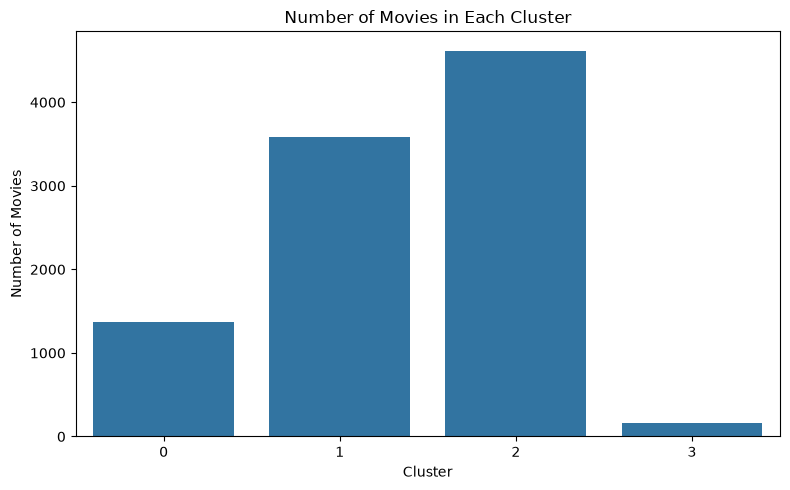

In [25]:
cluster_counts = (
    cluster_data["cluster"]
    .value_counts()
    .sort_index()
)

print("Number of movies in each cluster:")
display(cluster_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Movies in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

In [27]:

# Add movie genres to cluster_data
if "genres" not in cluster_data.columns:
    cluster_data = cluster_data.merge(
        movies_clean[["movieId", "genres"]],
        on="movieId",
        how="left"
    )

# Display movies in each cluster
for cluster_id in sorted(cluster_data["cluster"].unique()):
    print(f"\nCLUSTER {cluster_id}")

    cluster_movies = cluster_data[
        cluster_data["cluster"] == cluster_id
    ].sort_values(
        "average_rating",
        ascending=False
    )

    display(
        cluster_movies[
            ["title", "genres", "average_rating", "rating_count"]
        ].head(10)
    )



CLUSTER 0


,title,genres,average_rating,rating_count
3294,More (1998),Animation|Drama|Sci-Fi|IMAX,5.0,1.0
3759,Shogun Assassin (1980),Action|Adventure,5.0,1.0
9495,A Plasticine Crow (1981),Animation,5.0,1.0
9498,There Once Was a Dog (1982),Animation|Children|Comedy,5.0,1.0
9379,Winnie Pooh (1969),Animation|Children,5.0,1.0
9549,Cheburashka (1971),Animation,5.0,1.0
9380,Winnie the Pooh Goes Visiting (1971),Animation,5.0,1.0
9546,A Detective Story (2003),Animation|Sci-Fi,5.0,1.0
9544,Vovka in the Kingdom of Far Far Away (1965),Adventure|Animation|Children|Fantasy,5.0,1.0
9540,Winter in Prostokvashino (1984),Animation,5.0,1.0



CLUSTER 1


,title,genres,average_rating,rating_count
87,Heidi Fleiss: Hollywood Madam (1995),Documentary,5.0,2.0
9688,De platte jungle (1978),Documentary,5.0,1.0
6799,Watching the Detectives (2007),Comedy|Romance,5.0,1.0
2665,Bossa Nova (2000),Comedy|Drama|Romance,5.0,1.0
2639,All the Vermeers in New York (1990),Comedy|Drama|Romance,5.0,1.0
8839,Seve (2014),Documentary|Drama,5.0,1.0
8837,Buzzard (2015),Comedy|Drama|Horror,5.0,1.0
2597,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,Comedy,5.0,2.0
9388,"Wings, Legs and Tails (1986)",Animation|Comedy,5.0,1.0
7581,Connections (1978),Documentary,5.0,1.0



CLUSTER 2


,title,genres,average_rating,rating_count
5585,Sonatine (Sonachine) (1993),Action|Comedy|Crime|Drama,5.0,1.0
2611,Madame Sousatzka (1988),Drama,5.0,1.0
7364,Enter the Void (2009),Drama,5.0,2.0
8877,My Love (2006),Animation|Drama,5.0,1.0
4747,"Woman Under the Influence, A (1974)",Drama,5.0,1.0
121,"Awfully Big Adventure, An (1995)",Drama,5.0,1.0
5532,"Decalogue, The (Dekalog) (1989)",Crime|Drama|Romance,5.0,1.0
2947,Two Family House (2000),Drama,5.0,1.0
865,Entertaining Angels: The Dorothy Day Story (1996),Drama,5.0,1.0
2939,Sorority House Massacre II (1990),Horror,5.0,1.0



CLUSTER 3


,title,genres,average_rating,rating_count
8752,Trinity and Sartana Are Coming (1972),Comedy|Western,5.0,1.0
6101,7 Faces of Dr. Lao (1964),Fantasy|Mystery|Western,5.0,1.0
2835,Duel in the Sun (1946),Drama|Romance|Western,5.0,1.0
4836,"Ox-Bow Incident, The (1943)",Drama|Western,4.5,1.0
9111,Bone Tomahawk (2015),Horror|Western,4.5,2.0
7358,"Scalphunters, The (1968)",Comedy|Western,4.5,1.0
4973,Oklahoma! (1955),Musical|Romance|Western,4.5,2.0
7497,Sweetgrass (2009),Adventure|Documentary|Western,4.5,1.0
9267,Texas - Doc Snyder hält die Welt in Atem (1993),Comedy|Western,4.5,1.0
3259,"Man Who Shot Liberty Valance, The (1962)",Crime|Drama|Western,4.4,5.0


In [28]:
print(cluster_data.columns.tolist())

['movieId', 'title', '(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western', 'average_rating', 'rating_count', 'cluster', 'genres']


In [29]:
from sklearn.neighbors import NearestNeighbors

print("KNN recommendation tools are ready!")

KNN recommendation tools are ready!


In [30]:
knn_model = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(X_scaled)

print("KNN model trained successfully!")

KNN model trained successfully!


In [31]:
def recommend_similar_movies(movie_title, n_recommendations=5):

    # Find the selected movie
    matches = cluster_data[
        cluster_data["title"].str.contains(
            movie_title, case=False, regex=False, na=False
        )
    ]

    if matches.empty:
        print("Movie not found. Try another title.")
        return

    # Select the first matching movie
    movie_index = matches.index[0]

    # Find nearest movies
    distances, indices = knn_model.kneighbors(
        X_scaled[movie_index].reshape(1, -1),
        n_neighbors=min(n_recommendations + 1, len(cluster_data))
    )

    # Exclude the selected movie itself
    recommended_indices = [
        idx for idx in indices[0] if idx != movie_index
    ][:n_recommendations]

    # Display recommendations
    recommendations = cluster_data.iloc[recommended_indices]

    return recommendations[
        ["title", "average_rating", "rating_count"]
    ].reset_index(drop=True)

In [32]:
recommend_similar_movies("Toy Story", 5)

,title,average_rating,rating_count
0,"Monsters, Inc. (2001)",3.871212,132.0
1,Shrek (2001),3.867647,170.0
2,Finding Nemo (2003),3.960993,141.0
3,Toy Story 2 (1999),3.860825,97.0
4,"Incredibles, The (2004)",3.836000,125.0


In [33]:
recommend_similar_movies("Jumanji", 5)

,title,average_rating,rating_count
0,Harry Potter and the Sorcerer's Stone (a.k.a. ...,3.761682,107.0
1,"Chronicles of Narnia: The Lion, the Witch and ...",3.443548,62.0
2,"NeverEnding Story, The (1984)",3.581395,43.0
3,"Indian in the Cupboard, The (1995)",3.235294,34.0
4,Addams Family Values (1993),3.101190,84.0


In [34]:
# Combine movie statistics with genre features

regression_data = movie_stats.merge(
    genre_features.assign(
        movieId=movies_features["movieId"].values
    ),
    on="movieId",
    how="left"
)

# Remove movies without actual ratings
regression_data = regression_data.dropna(
    subset=["average_rating"]
).copy()

print("Regression dataset shape:", regression_data.shape)
display(regression_data.head())

Regression dataset shape: (9724, 25)


,movieId,average_rating,rating_count,title,genres,(no genres listed),Action,Adventure,Animation,Children,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select input features
genre_columns = genre_features.columns.tolist()

X = regression_data[genre_columns + ["rating_count"]]
y = regression_data["average_rating"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7779
Testing samples: 1945


In [36]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Linear Regression Results")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Linear Regression Results
MAE: 0.6083183500679804
MSE: 0.6228310734575844
R2 Score: 0.10881664204714225


In [37]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

# One-feature model: rating count predicts average rating
X_gd = regression_data[["rating_count"]].values
y_gd = regression_data["average_rating"].values

# Split data
X_gd_train, X_gd_test, y_gd_train, y_gd_test = train_test_split(
    X_gd, y_gd, test_size=0.2, random_state=42
)

# Scale using training data only
gd_scaler = StandardScaler()
X_gd_train = gd_scaler.fit_transform(X_gd_train)
X_gd_test = gd_scaler.transform(X_gd_test)

print("Gradient Descent data prepared.")

Gradient Descent data prepared.


In [38]:
# Initialize parameters
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000

m = len(X_gd_train)
cost_history = []

for epoch in range(epochs):

    # Predictions
    y_hat = w * X_gd_train.ravel() + b

    # Prediction errors
    errors = y_hat - y_gd_train

    # Cost function
    cost = np.sum(errors ** 2) / (2 * m)
    cost_history.append(cost)

    # Gradients
    dw = np.sum(errors * X_gd_train.ravel()) / m
    db = np.sum(errors) / m

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("Final weight:", w)
print("Final bias:", b)
print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])

Final weight: 0.11036040488780675
Final bias: 3.2629723627680574
Initial cost: 5.709470149520202
Final cost: 0.3794259306958939


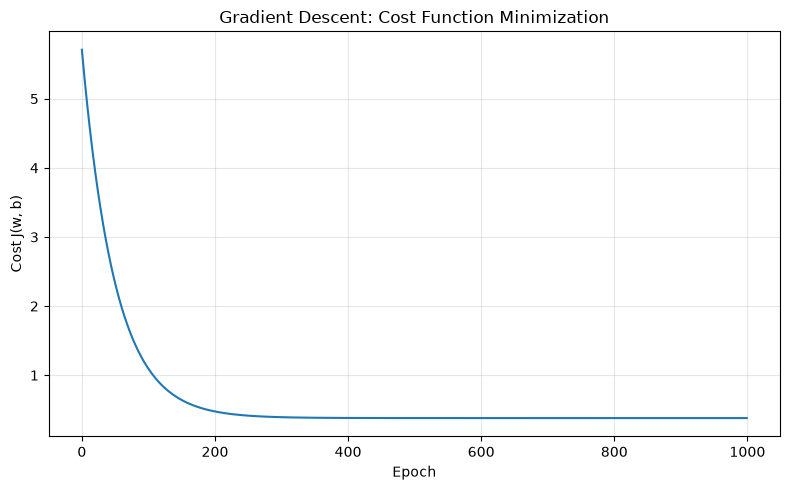

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.title("Gradient Descent: Cost Function Minimization")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w, b)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
y_gd_pred = w * X_gd_test.ravel() + b

print("Gradient Descent Evaluation")
print("MAE:", mean_absolute_error(y_gd_test, y_gd_pred))
print("MSE:", mean_squared_error(y_gd_test, y_gd_pred))
print("R2 Score:", r2_score(y_gd_test, y_gd_pred))

Gradient Descent Evaluation
MAE: 0.6507007131898807
MSE: 0.6863682593536788
R2 Score: 0.0179038968505707


In [41]:
import pandas as pd
import numpy as np

# Combine ratings with movie information
classification_data = ratings_clean.merge(
    movies_clean[["movieId", "title", "genres"]],
    on="movieId",
    how="inner"
)

# Convert ratings into binary labels
classification_data["liked"] = (
    classification_data["rating"] >= 4.0
).astype(int)

print("Classification dataset:")
display(classification_data.head())

print("\nClass distribution:")
print(classification_data["liked"].value_counts())

Classification dataset:


,userId,movieId,rating,timestamp,title,genres,liked
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance,1
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller,1
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,1
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,1



Class distribution:
liked
0    52256
1    48580
Name: count, dtype: int64


In [42]:
from sklearn.model_selection import train_test_split

# Split individual ratings first
train_ratings, test_ratings = train_test_split(
    classification_data,
    test_size=0.2,
    random_state=42,
    stratify=classification_data["liked"]
)

# Calculate average ratings from training data only
training_movie_means = train_ratings.groupby("movieId")["rating"].mean()

# Build genre features for each rating
genre_matrix = movies_clean.set_index("movieId")["genres"].fillna("")
genre_matrix = genre_matrix.str.get_dummies(sep="|")

# Align genre columns with all ratings
genre_matrix = genre_matrix.reindex(
    classification_data["movieId"].unique(),
    fill_value=0
)

print("Training records:", len(train_ratings))
print("Testing records:", len(test_ratings))
print("Genre features:", genre_matrix.shape[1])

Training records: 80668
Testing records: 20168
Genre features: 20


In [43]:
from sklearn.preprocessing import StandardScaler

genre_columns = genre_matrix.columns.tolist()

def make_features(data):
    # Get genre features for each movie
    genre_part = data["movieId"].map(
        lambda mid: genre_matrix.loc[mid].to_numpy()
    )

    genre_df = pd.DataFrame(
        genre_part.tolist(),
        columns=genre_columns,
        index=data.index
    )

    # Use training-only movie averages
    avg_rating = data["movieId"].map(training_movie_means)

    # Unseen movies use the overall training mean
    avg_rating = avg_rating.fillna(train_ratings["rating"].mean())

    genre_df["training_avg_rating"] = avg_rating

    return genre_df

X_train_cls = make_features(train_ratings)
X_test_cls = make_features(test_ratings)

y_train_cls = train_ratings["liked"]
y_test_cls = test_ratings["liked"]

# Scale using training data only
scaler_cls = StandardScaler()
X_train_scaled = scaler_cls.fit_transform(X_train_cls)
X_test_scaled = scaler_cls.transform(X_test_cls)

print("Classification features prepared.")

Classification features prepared.


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train_cls)

log_predictions = log_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test_cls, log_predictions))

print("\nClassification Report:")
print(classification_report(y_test_cls, log_predictions))

Logistic Regression Accuracy: 0.6489488298294328

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.66      0.66     10452
           1       0.64      0.64      0.64      9716

    accuracy                           0.65     20168
   macro avg       0.65      0.65      0.65     20168
weighted avg       0.65      0.65      0.65     20168



In [45]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

tree_model.fit(X_train_cls, y_train_cls)

tree_predictions = tree_model.predict(X_test_cls)

print("Decision Tree Accuracy:",
      accuracy_score(y_test_cls, tree_predictions))

print("\nClassification Report:")
print(classification_report(y_test_cls, tree_predictions))

Decision Tree Accuracy: 0.6479571598571995

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.67      0.66     10452
           1       0.64      0.63      0.63      9716

    accuracy                           0.65     20168
   macro avg       0.65      0.65      0.65     20168
weighted avg       0.65      0.65      0.65     20168



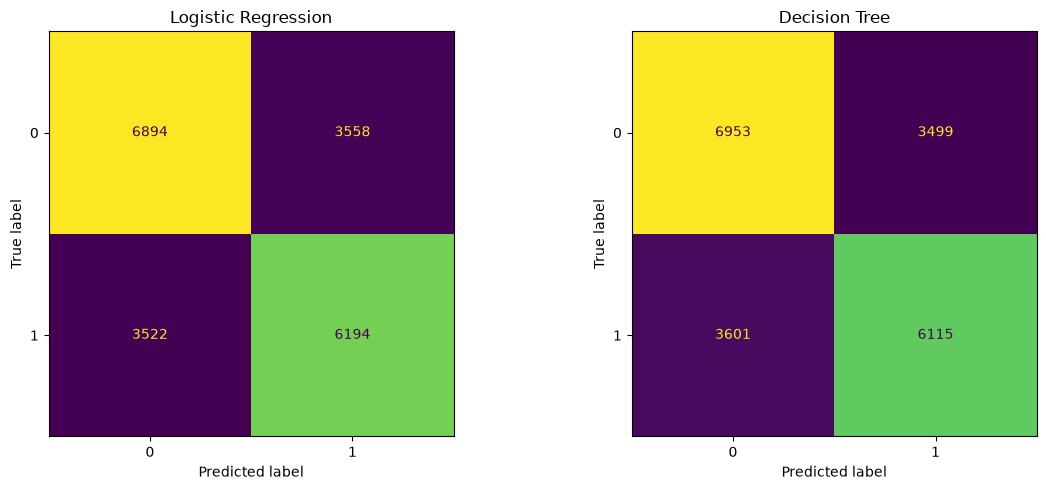

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    log_predictions,
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    tree_predictions,
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()

In [2]:
%pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import mlxtend

print("mlxtend version:", mlxtend.__version__)

from mlxtend.frequent_patterns import apriori, association_rules

print("Association Rule Learning is ready!")

mlxtend version: 0.25.0
Association Rule Learning is ready!


In [3]:
import sys
print(sys.executable)

E:\Anaconda\python.exe


In [4]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("Association Rule Learning is ready!")

Association Rule Learning is ready!


In [6]:
import pandas as pd

movies = pd.read_csv(r"C:\Users\intel\Desktop\Movie Recoomendation\ml-latest-small\movies.csv")
ratings = pd.read_csv(r"C:\Users\intel\Desktop\Movie Recoomendation\ml-latest-small\ratings.csv")

print("Movies loaded:", movies.shape)
print("Ratings loaded:", ratings.shape)

Movies loaded: (9742, 3)
Ratings loaded: (100836, 4)


In [7]:
# Create working copies
movies_clean = movies.copy()
ratings_clean = ratings.copy()

# Remove duplicate rows
movies_clean = movies_clean.drop_duplicates()
ratings_clean = ratings_clean.drop_duplicates()

# Remove rows missing essential fields
movies_clean = movies_clean.dropna(
    subset=["movieId", "title"]
)

ratings_clean = ratings_clean.dropna(
    subset=["userId", "movieId", "rating"]
)

# Keep valid MovieLens ratings
valid_rating = (
    ratings_clean["rating"].between(0.5, 5.0)
    & ((ratings_clean["rating"] * 2) % 1 == 0)
)

ratings_clean = ratings_clean[valid_rating].copy()

print("Clean movies:", movies_clean.shape)
print("Clean ratings:", ratings_clean.shape)

Clean movies: (9742, 3)
Clean ratings: (100836, 4)


In [8]:
liked_ratings = ratings_clean[
    ratings_clean["rating"] >= 4.0
].copy()

In [9]:
liked_ratings = ratings_clean[
    ratings_clean["rating"] >= 4.0
].copy()

liked_ratings = liked_ratings.drop_duplicates(
    subset=["userId", "movieId"]
)

liked_ratings = liked_ratings.merge(
    movies_clean[["movieId", "title"]],
    on="movieId",
    how="inner"
)

user_movie_matrix = liked_ratings.pivot_table(
    index="userId",
    columns="title",
    values="rating",
    aggfunc="max"
).notna()

print("Transaction matrix:", user_movie_matrix.shape)

Transaction matrix: (609, 6297)


In [10]:
from mlxtend.frequent_patterns import apriori

movie_support = user_movie_matrix.mean(axis=0)

popular_movies = movie_support[
    movie_support >= 0.02
].index

transactions = user_movie_matrix[popular_movies]

frequent_itemsets = apriori(
    transactions,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

display(frequent_itemsets.head(10))

,support,itemsets
0,0.042693,frozenset({(500) Days of Summer (2009)})
1,0.041051,frozenset({10 Things I Hate About You (1999)})
2,0.031199,frozenset({101 Dalmatians (One Hundred and One...
3,0.080460,frozenset({12 Angry Men (1957)})
4,0.022989,frozenset({127 Hours (2010)})
5,0.124795,frozenset({2001: A Space Odyssey (1968)})
6,0.029557,frozenset({21 Jump Street (2012)})
7,0.022989,frozenset({25th Hour (2002)})
8,0.065681,frozenset({28 Days Later (2002)})
9,0.062397,frozenset({300 (2007)})


In [11]:
from mlxtend.frequent_patterns import association_rules

if frequent_itemsets.empty:
    print("No frequent itemsets found. Try lowering min_support.")
else:
    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.1
    )

    if rules.empty:
        print("No association rules found. Try lowering the threshold.")
    else:
        rules = rules.sort_values(
            "lift",
            ascending=False
        )

        display(
            rules[
                ["antecedents", "consequents",
                 "support", "confidence", "lift"]
            ].head(10)
        )

,antecedents,consequents,support,confidence,lift
176221,"frozenset({Alien (1979), Road Warrior, The (Ma...",frozenset({Mad Max (1979)}),0.022989,0.636364,24.221591
176224,frozenset({Mad Max (1979)}),"frozenset({Alien (1979), Road Warrior, The (Ma...",0.022989,0.875000,24.221591
1453894,frozenset({Mad Max (1979)}),"frozenset({Road Warrior, The (Mad Max 2) (1981...",0.021346,0.812500,23.562500
1453893,"frozenset({Road Warrior, The (Mad Max 2) (1981...",frozenset({Mad Max (1979)}),0.021346,0.619048,23.562500
1453886,"frozenset({Mad Max (1979), Saving Private Ryan...","frozenset({Road Warrior, The (Mad Max 2) (1981)})",0.021346,1.000000,22.555556
1453890,"frozenset({Road Warrior, The (Mad Max 2) (1981)})","frozenset({Mad Max (1979), Saving Private Ryan...",0.021346,0.481481,22.555556
1453888,"frozenset({Saving Private Ryan (1998), Road Wa...",frozenset({Mad Max (1979)}),0.021346,0.590909,22.491477
1453889,frozenset({Mad Max (1979)}),"frozenset({Saving Private Ryan (1998), Road Wa...",0.021346,0.812500,22.491477
1453895,"frozenset({Road Warrior, The (Mad Max 2) (1981)})","frozenset({Mad Max (1979), Terminator, The (19...",0.021346,0.481481,20.944444
1453892,"frozenset({Mad Max (1979), Terminator, The (19...","frozenset({Road Warrior, The (Mad Max 2) (1981)})",0.021346,0.928571,20.944444


In [12]:
def recommend_by_association(movie_title, n=5):
    if "rules" not in globals() or rules.empty:
        print("No association rules available.")
        return

    matches = rules[
        rules["antecedents"].apply(
            lambda items: any(
                movie_title.lower() in title.lower()
                for title in items
            )
        )
    ].sort_values("lift", ascending=False)

    recommendations = []

    for _, rule in matches.iterrows():
        for title in rule["consequents"]:
            if title.lower() != movie_title.lower():
                if title not in recommendations:
                    recommendations.append(title)

            if len(recommendations) >= n:
                break

        if len(recommendations) >= n:
            break

    if not recommendations:
        print("No recommendations found for this title.")
        return

    return pd.DataFrame({
        "Recommended Movie": recommendations
    })

In [13]:
recommend_by_association("Toy Story", 5)

,Recommended Movie
0,Pinocchio (1940)
1,"Karate Kid, The (1984)"
2,Wallace & Gromit: The Wrong Trousers (1993)
3,"Fistful of Dollars, A (Per un pugno di dollari..."
4,Hero (Ying xiong) (2002)


In [19]:
# Display example movies and their average ratings

movie_evaluation = (
    ratings_clean
    .groupby("movieId")
    .agg(
        average_rating=("rating", "mean"),
        total_ratings=("rating", "count")
    )
    .reset_index()
    .merge(
        movies_clean[["movieId", "title"]],
        on="movieId",
        how="left"
    )
)

# Consider movies with at least 20 ratings
movie_evaluation = movie_evaluation[
    movie_evaluation["total_ratings"] >= 20
]

movie_evaluation = movie_evaluation.sort_values(
    by="average_rating",
    ascending=False
)

movie_evaluation.head(10).round(2)

,movieId,average_rating,total_ratings,title
840,1104,4.47,20,"Streetcar Named Desire, A (1951)"
277,318,4.43,317,"Shawshank Redemption, The (1994)"
704,922,4.33,27,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)
680,898,4.31,29,"Philadelphia Story, The (1940)"
905,1204,4.30,45,Lawrence of Arabia (1962)
413,475,4.30,25,In the Name of the Father (1993)
210,246,4.29,29,Hoop Dreams (1994)
659,858,4.29,192,"Godfather, The (1972)"
934,1235,4.29,26,Harold and Maude (1971)
9445,168252,4.28,25,Logan (2017)


In [20]:
%whos

Variable                   Type                  Data/Info
----------------------------------------------------------
LogisticRegression         type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
accuracy_score             function              <function accuracy_score at 0x000001E4D15D64B0>
apriori                    function              <function apriori at 0x000001E4BC573110>
association_rules          function              <function association_rul<...>es at 0x000001E4BC573480>
classification_report      function              <function classification_<...>rt at 0x000001E4D15D7A00>
f1_score                   function              <function f1_score at 0x000001E4D15D6E50>
frequent_itemsets          DataFrame             Shape: (314538, 2)
liked_ratings              DataFrame             Shape: (48580, 5)
log_model                  LogisticRegression    LogisticRegression(max_iter=1000)
mlxtend                    module                <module 'mlxtend' from

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate average rating and rating count for each movie
regression_data = (
    ratings_clean.groupby("movieId")
    .agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count")
    )
    .reset_index()
)

# Add movie genres
regression_data = regression_data.merge(
    movies_clean[["movieId", "genres"]],
    on="movieId",
    how="left"
)

# Convert genres into numerical features
genre_features = (
    regression_data["genres"]
    .fillna("")
    .str.get_dummies(sep="|")
)

X = pd.concat(
    [
        genre_features,
        regression_data[["rating_count"]].reset_index(drop=True)
    ],
    axis=1
)

y = regression_data["average_rating"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression
regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

# Predict average movie ratings
y_pred = regression_model.predict(X_test)

# Evaluate the model
print("Linear Regression Evaluation")
print("-----------------------------")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("MSE:", round(mean_squared_error(y_test, y_pred), 3))
print("R² Score:", round(r2_score(y_test, y_pred), 3))

Linear Regression Evaluation
-----------------------------
MAE: 0.608
MSE: 0.623
R² Score: 0.109


In [22]:
%whos

Variable                   Type                  Data/Info
----------------------------------------------------------
LinearRegression           ABCMeta               <class 'sklearn.linear_mo<...>._base.LinearRegression'>
LogisticRegression         type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
X                          DataFrame             Shape: (9724, 21)
X_test                     DataFrame             Shape: (1945, 21)
X_train                    DataFrame             Shape: (7779, 21)
accuracy_score             function              <function accuracy_score at 0x000001E4D15D64B0>
apriori                    function              <function apriori at 0x000001E4BC573110>
association_rules          function              <function association_rul<...>es at 0x000001E4BC573480>
classification_report      function              <function classification_<...>rt at 0x000001E4D15D7A00>
f1_score                   function              <function f1_score at 0x0

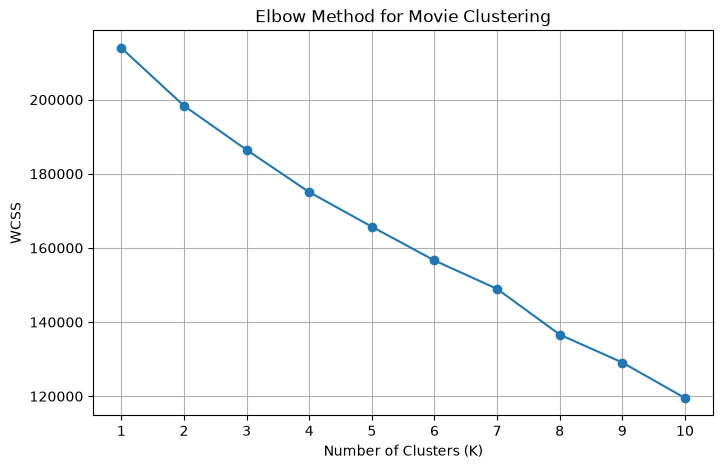

In [23]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Prepare movie-level features
cluster_stats = (
    ratings_clean.groupby("movieId")
    .agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count")
    )
    .reset_index()
)

cluster_movies = movies_clean.merge(
    cluster_stats, on="movieId", how="inner"
)

# Convert genres into numerical features
cluster_genres = (
    cluster_movies["genres"]
    .fillna("")
    .str.get_dummies(sep="|")
)

cluster_features = pd.concat(
    [
        cluster_genres.reset_index(drop=True),
        cluster_movies[
            ["average_rating", "rating_count"]
        ].reset_index(drop=True)
    ],
    axis=1
)

# Scale features
X_cluster_scaled = StandardScaler().fit_transform(
    cluster_features
)

# Calculate WCSS for different K values
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_cluster_scaled)
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Movie Clustering")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()